# Teaching a supervisor agent to triage its own inbox

Agents are great at hard questions, and a little overkill for easy ones. In this notebook we put a small, fast classifier in front of a **supervisor agent**. Before the supervisor sees a message, the classifier decides whether to answer it as-is, tidy it up, split it into pieces, or ask the user what they meant.

**What you'll build**

1. Two tools: web search and live forex rates
2. A middleware "bouncer" powered by **Jev**
3. A supervisor that delegates to two subagents
4. A few test queries that show where it shines, and where it stumbles

**What you'll need:** API keys for OpenAI, Tavily, TypeSafe and LangSmith, saved in a `.env` file.

Let's go 👇

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import getpass
import os
from warnings import filterwarnings

from dotenv import find_dotenv, load_dotenv

filterwarnings("ignore")

_ = load_dotenv(find_dotenv())

def check_envs():
    """Quick check if all your required API keys are in your environment."""
    if "OPENAI_API_KEY" not in os.environ:
        os.environ["OPENAI_API_KEY"] = getpass.getpass("Enter your OpenAI API key: ")
    if "TAVILY_API_KEY" not in os.environ:
        os.environ["TAVILY_API_KEY"] = getpass.getpass("Enter your Tavily API key: ")
    if "TYPESAFE_API_KEY" not in os.environ:
        os.environ["TYPESAFE_API_KEY"] = getpass.getpass("Enter your Typesafe API key: ")
    if "LANGSMITH_API_KEY" not in os.environ:
        os.environ["LANGSMITH_API_KEY"] = getpass.getpass("Enter your Langsmith API key: ")

check_envs()

## Step 1: Give the agents something to work with

Every agent needs a brain and some tools. We'll use a single OpenAI model for everything (supervisor, subagents, and the middleware's helper calls), plus two tools: a web search and a forex lookup.

In [3]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-6-luna")

### 🔎 Tool #1: web search with Tavily

Tavily is a search API built for LLMs. We cap it at 5 results.

> 💡 **Why cap it?** Every search result lands in the model's context. Fewer results means fewer input tokens, which means faster and cheaper runs.

In [4]:
from langchain_tavily import TavilySearch

tavily_tool = TavilySearch(
    max_results=5,
    topic="general",
    include_answer=False,
    search_depth="basic",
)

### 💱 Tool #2: live exchange rates

A small wrapper around the free Frankfurter API.

> 💡 **The docstring is part of the tool.** The LLM reads it to decide when and how to call the function. Write it like you're briefing a smart intern who can't ask follow-up questions.

In [5]:
import requests
from langchain.tools import tool


@tool
def get_forex_exchange_rate(base_currency: str, target_currencies: list[str]) -> dict[str, float]:
    """
    Get the current forex exchange rate between two currencies.

    Args:
        base_currency (str): The base currency code (e.g., "USD").
        target_currencies (list[str]): A list of target currency codes (e.g., ["EUR", "GBP"]).

    Returns:
        dict[str, float]: A dictionary mapping each target currency to its exchange rate.
    """
    res = requests.get(
        "https://api.frankfurter.dev/v2/rates",
        params={"base": base_currency, "quotes": ",".join(target_currencies)},
        timeout=10,
    )
    rates = {row["quote"]: row["rate"] for row in res.json()}
    return rates

## Step 2: Build the bouncer 🕵️

Not every question needs a full agent run. Some are crisp, some are messy, some are really two questions in a trench coat. So before the supervisor sees a message, we'll let a fast classifier, **Jev** (TypeSafe's classifier model), triage it and pick one of four labels:

| Label | What it means | What the middleware does |
|---|---|---|
| `direct` | Clear, single question | Nothing. Pass it straight through |
| `decomposable` | Several distinct questions in one | Splits it up and tells the supervisor to fan out to subagents |
| `enrichable` | Understandable, but sloppy | Rewrites it to be clearer |
| `needs_clarification` | Missing information only the user has | Tells the supervisor to ask the user what they meant |

How it works:

- It's **middleware**. The `before_agent` hook runs before the agent does anything. It pulls the query out of the last message *once*, so every helper just takes a plain `str`.
- **Confidence gate.** The middleware only acts when Jev is at least **80%** sure (`threshold=0.80`). Below that, or on `direct`, it returns `None` and the message goes through untouched.
- The result is added as a **new message** after the original, so the supervisor sees both.

> 👀 **Keep the 80% gate in mind.** It matters a lot in the last section.

In [ ]:
from typing import Any

from langchain.agents.middleware import AgentMiddleware, AgentState
from langchain.messages import HumanMessage
from langchain_typesafe import Choice, TypeSafeClassifier
from langchain_typesafe.types import ClassifierResponse
from langgraph.runtime import Runtime


class QueryEnrichmentMiddleware(AgentMiddleware):
    """
    Middleware to enrich, decompose, or clarify user queries before they are processed by the agent.
    We are using this middleware to help the supervisor be more efficient.
    """
    
    def __init__(self, llm, classifier = None, threshold: float = 0.80):
        super().__init__()
        self.llm = llm
        self.classifier = classifier or TypeSafeClassifier()
        self.threshold = threshold
        self.handlers = {
            "decomposable": self.decompose_query,
            "enrichable": self.enrich_query,
            "needs_clarification": self.clarify_query,
        }
    
    def enrich_query(self, query: str) -> str:
        """Helper function to enrich user queries"""
        return self.llm.invoke(
            "Rewrite the following user query for clarity. "
            "Preserve the original meaning and all explicit constraints. "
            "Do not invent missing details or answer the question. "
            "Return only the rewritten query.\n\n"
            f"User query: {query}"
        ).content
    
    def decompose_query(self, query: str) -> str:
        """Helper function to decompose user queries"""
        sub_queries = self.llm.invoke(
            f"The user's query is: {query}. "
            "Your role is to decompose this query into sub-queries that can be answered separately. "
        )
        return (
            f"Original user query: {query}\n\n"
            f"Suggested sub-questions:\n{sub_queries.content}\n\n"
            "Use these sub-questions to guide your analysis. "
            "Combine related operations where appropriate, "
            "and synthesize the results into a single response."
        )

    def query_classify(self, query: str) -> ClassifierResponse:
        """Helper function to classify user queries using Jev"""
        return self.classifier.invoke(
            {
                "state": query,
                "questions": {
                    "next_action": Choice(
                        instructions = "Should this query be decomposed into multiple sub-queries?",
                        criteria = {
                            "decomposable": "Does the query have multiple distinct sub-queries that can be answered separately?",
                            "direct": "Is the query a single, direct question that can be answered without additional context or information?",
                            "enrichable": "Should the query be re-written to be clearer so that it can be answered more effectively?",
                            "needs_clarification": "Does the query require additional context or clarification before it can be answered?",
                        }
                    )
                }
            }
        )
        
    def clarify_query(self, query: str) -> str:
        """Helper function to inject prompt to clarify user queries"""
        return (
            f"Original user query: {query}\n\n"
            "The request may be ambiguous or missing essential information. "
            "Ask the user one concise clarification question before proceeding. "
            "Do not assume missing details."
        )

    def before_agent(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        """
        LangChain middleware hook that executes before the agent processes the user query. 
        It classifies the query and decides whether to enrich, decompose, or clarify it.
        """
        messages = state["messages"]
        if not messages or not isinstance(messages[-1], HumanMessage):
            return None
        query = messages[-1].text

        next_action = self.query_classify(query).choices["next_action"]
        handler = self.handlers.get(next_action.choice)
        if next_action.confidence < self.threshold or handler is None:
            return None
        return {
            "messages": [
                HumanMessage(
                    content=handler(query), 
                    id = messages[-1].id
                )
            ]
        }

## Step 3: Check the bouncer on its own

Before wiring it into an agent, let's test it in isolation. Here's a question that's *obviously* two questions: one about exchange rates, one about central-bank news. Jev should flag it as `decomposable`.

In [7]:
decomposable_query = "What is the current exchange rate between USD and EUR, and can you also provide the latest news on the European Central Bank's monetary policy?"

### 🧪 Sanity check

This calls only the classifier. No agent, no tools, a fraction of a second. You should see `decomposable` with a confidence at or near `1.0`.

In [8]:
query_middleware = QueryEnrichmentMiddleware(llm=llm)
response = query_middleware.query_classify(query=decomposable_query)
print(response.choices["next_action"].choice, response.choices["next_action"].confidence)

/var/folders/zb/r15p7t_d62d8m2s0623s22gh0000gn/T/ipykernel_69406/2039298670.py:19: LangChainBetaWarning: The class `TypeSafeClassifier` is in beta. It is actively being worked on, so the API may change.
  self.classifier = classifier or TypeSafeClassifier()


decomposable 1.0


## Step 4: Assemble the agent 🏗️

Now the main event: a **supervisor** that delegates to two specialists.

- **`Forex_Expert`** has one tool: the exchange-rate lookup.
- **`Web_search`** has one tool: Tavily.
- The supervisor has **no tools of its own** (see the comment in the code). It can only delegate. `SubAgentMiddleware` wraps each subagent as a tool the supervisor can call.
- Our query middleware sits in front of all of it.

We also add a SQLite **checkpointer**, so conversations are saved to `jever.db`.

> 💡 **Tip:** a checkpointer replays the history of a `thread_id`. If you're experimenting and something gets weird, switch to a fresh `thread_id` so old messages don't tag along.

In [9]:
import sqlite3

from deepagents.backends import StateBackend
from deepagents.middleware import SubAgentMiddleware
from langchain.agents import create_agent
from langgraph.checkpoint.sqlite import SqliteSaver

subagent_middleware = SubAgentMiddleware(
    backend=StateBackend(),
    subagents = [
        {
            "name": "Forex_Expert",
            "description": "An expert in forex exchange rates and currency markets.",
            "tools": [get_forex_exchange_rate],
            "model": llm,
        },
        {
            "name": "Web_search",
            "description": "An expert in searching the web for information.",
            "tools": [tavily_tool],
            "model": llm,
        },
    ]
)

conn = sqlite3.connect("jever.db", check_same_thread=False)
checkpointer = SqliteSaver(conn)

agent = create_agent(
    model = llm,
    tools = [], # LOOK NO TOOLS!
    middleware = [query_middleware, subagent_middleware],
    checkpointer=checkpointer,
)

### 🗺️ The graph looks strange, and that's fine

The supervisor's `model` node shows no tools of ours. That's expected: `SubAgentMiddleware` wraps each subagent as a tool for the supervisor behind the scenes, so you won't see them listed here.

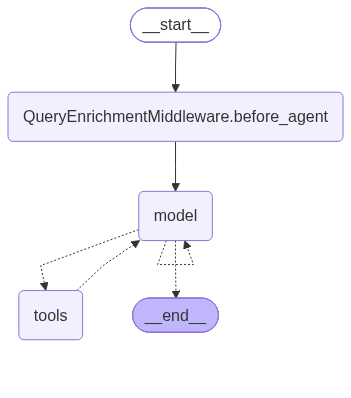

In [10]:
from IPython.display import Image, Markdown, display

display(Image(agent.get_graph(xray=True).draw_mermaid_png()))

## Step 5: Run it 🚀

Send the two-part question to the agent.

- The input must be `{"messages": [...]}`. A bare string won't work.
- Expect **a few minutes**. The supervisor will fan out to both subagents, and the web search is the slow part.
- Tip: open the run in LangSmith while you wait and watch it work.

In [11]:
response = agent.invoke(
    {"messages": [ HumanMessage(content=decomposable_query),]},
    {"configurable": {"thread_id": "thread-4",}}
)

### 📜 Read the answer

The reply content comes back as a list of blocks, not a plain string, so we grab the text from the last block and render it as Markdown.

In [12]:
display(Markdown(response['messages'][-1].content[-1]['text']))

**USD to EUR:** The latest rate lookup returned **US$1 ≈ €0.8920**. It did not provide a source or update timestamp, so I can’t verify that it is a live rate. The ECB’s [reference rates](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html) may differ from market quotes.

**ECB monetary policy:** As of **15 October 2026**, the latest rate decision I could verify was on **10 September**. The ECB raised its key rates by 0.25 percentage point, effective 16 September: the deposit rate to **2.50%**, main refinancing rate to **2.65%**, and marginal lending rate to **2.90%**. It said future decisions would depend on incoming data, with no preset rate path. On 8 October, policymaker Primož Dolenc said further tightening might be needed, but that was a comment—not a new ECB decision. The next scheduled policy meeting is **29 October**.

Sources: [ECB rate decision](https://www.ecb.europa.eu/press/pr/date/2026/html/ecb.mp260910~314e508016.en.html) · [ECB meeting calendar](https://www.ecb.europa.eu/press/calendars/mgcgc/html/index.en.html) · [Reuters on Dolenc’s comments](https://www.reuters.com/world/europe/with-inflation-risks-upside-ecb-may-need-hike-more-dolenc-says-2026-10-08)

Now let's look at what our traces tell us

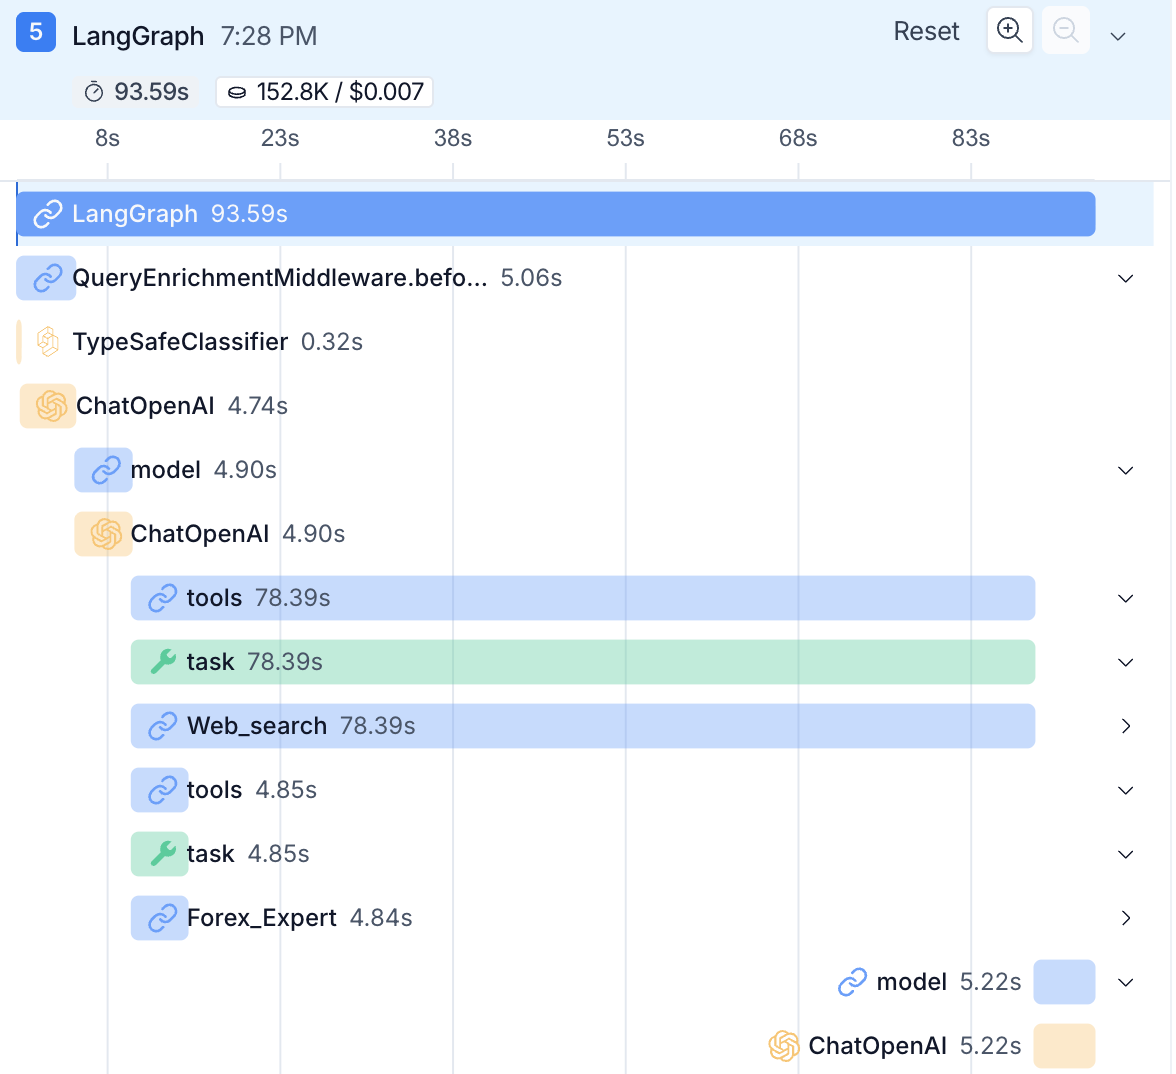

In [13]:
display(Image("../images/baseline_trace.png"))

OK everything ran. Both subagents (`Web_search` and `Forex_Expert`) kicked off at the same time, the agent then consolidated the reply.

> Jev Gap: Jev is unable to consolidate the subagents' responses into a single, coherent reply.

Also, Jev does not possess the raw intelligence of an LLM. In this trace, the supervisor agent called for the `Web_search` subagent to verify something one of its previous subagents gave it. 

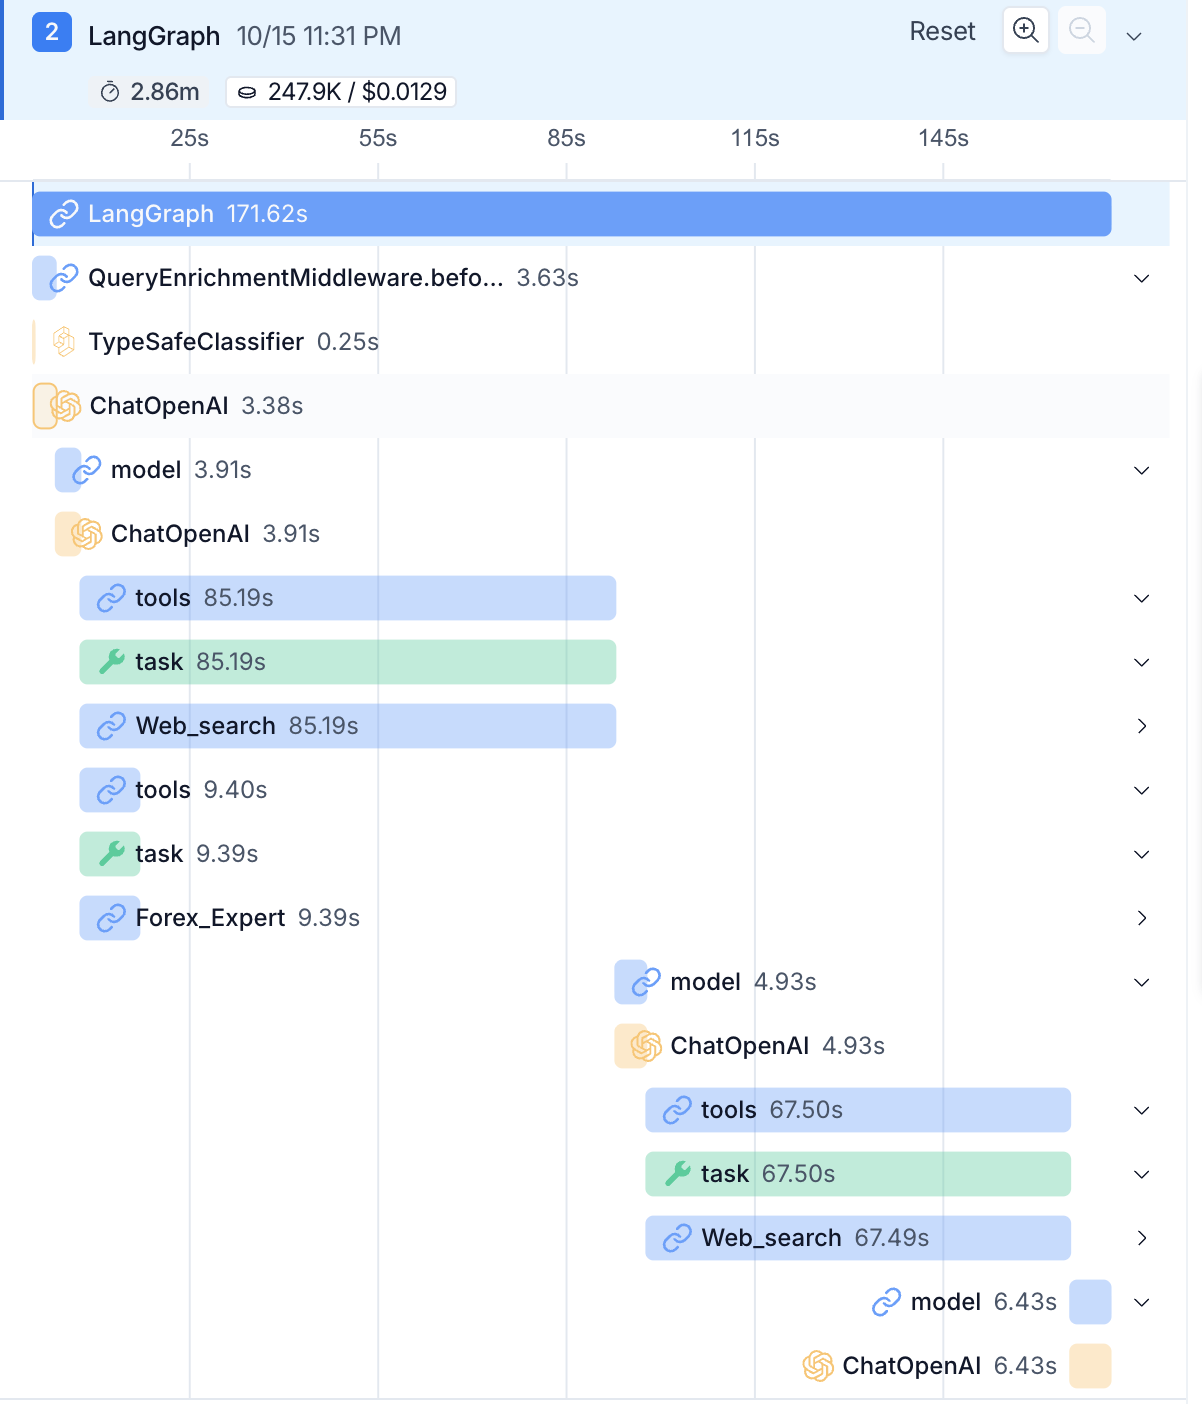

In [14]:
display(Image("../images/trace_decompose_query.png"))

### 🔍 What just happened? (LangSmith trace)

Read the trace top to bottom:

1. **The bouncer** classified the question as `decomposable` and rewrote it as an instruction to spawn subagents.
2. **The supervisor fanned out**, calling `Forex_Expert` and `Web_search` *at the same time*. Forex finished in about 9 seconds, and the web search kept going for about 85.
3. **It double-checked itself.** After reading both results, it called `Web_search` once more to verify a claim, then combined everything into one answer.

**The takeaway:** Jev decides *how a question gets handed off*. The reasoning, the fact-checking and the final write-up are the supervisor LLM's job. That's why Jev belongs **in front of** the supervisor, not **in place of** it: it's great at fast routing, and an LLM is better when the question calls for thinking.

> ⏱️ **A note on cost:** this run took about 2.9 minutes and used about 248K tokens. That extra verification round isn't free.

## Step 6: Where does the bouncer struggle? 🎭

One happy-path test isn't enough. Let's try one query per remaining label:

- **`direct`**: a clean, simple question.
- **`enrichable`**: a messy, Singlish-flavoured question that's understandable but needs tidying.
- **`needs_clarification`**: keyboard mash. There's nothing to answer here.

(We skip `decomposable`, since the main run above already covered it.)

In [15]:
direct_query = "What is the current exchange rate between USD and EUR?"
enrichable_query = "Usain Bolt fast how training he?"
needs_clarification_query = "fasdlkfaleuraoi34"

### 🔁 Run them all

Each query goes through the full agent on its **own** `thread_{i}`, so one test's history can't leak into the next. The final answers are collected in `answers`.

In [16]:
tests = [direct_query, enrichable_query, needs_clarification_query]
answers = []
for i, test in enumerate(tests):
    response = agent.invoke(
        {"messages": [ HumanMessage(content=test),]},
        {"configurable": {"thread_id": f"thread_{i}",}}
    )
    answers.append(response['messages'][-1].content[-1]['text'])

### 🪞 Compare the answers

Render each answer and compare it with what you'd *expect* for that label. Pay special attention to the middle one.

In [17]:
for _ in answers:
    display(Markdown(_))
    display(Markdown("---"))

The latest rate available to me is **1 USD ≈ 0.8916 EUR**. The quote’s source and timestamp weren’t provided, so I can’t confirm it’s live.

---

Bolt trained for **explosive speed**, not long-distance running. With his coach, he practiced sprint starts and short, very fast runs, then did strength, jumping, and technique exercises. He also rested and recovered between hard sessions. His natural talent helped too.

---

What would you like me to do with “fasdlkfaleuraoi34”?

---

### ⚠️ The catch: confidence thresholds

For the `enrichable` query, Jev's confidence was only **43%**. Our middleware only acts at **80% or higher**, so it stood down and passed the Singlish straight to the supervisor. The supervisor then didn't give us a clear answer to the question we meant: *"How do we train to be as fast as Usain Bolt?"*

What to take from this:

- **The gate is our design choice, not Jev's.** A 43% confidence can still be the top label among four options, so check the classifier's **Probabilities** in LangSmith. Lowering the threshold, or acting on the top label whenever it leads by a clear margin, may rescue cases like this.
- **It's one query.** Heavy Singlish is a fair stress test, but a single example isn't a verdict.

> Fair warning: pick your threshold on purpose, and test it with messy, real-world inputs, not just clean ones.

## Baseline agent

In [19]:
baseline_agent = create_agent(
    model = llm,
    tools = [], # LOOK NO TOOLS!
    middleware = [subagent_middleware],
    checkpointer=checkpointer,
)

baseline_tests = [decomposable_query, direct_query, enrichable_query, needs_clarification_query]
baseline_answers = []
for i, test in enumerate(baseline_tests):
    response = baseline_agent.invoke(
        {"messages": [ HumanMessage(content=test),]},
        {"configurable": {"thread_id": f"baseline_thread_{i}_",}}
    )
    baseline_answers.append(response['messages'][-1].content[-1]['text'])